# Electric Vehicles vs. Fuel-Powered Vehicles
Comparing EV adoption, yearly fuel/charging costs and CO2 emissions in the United States.

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import seaborn as sb
from matplotlib import rcParams

rcParams["figure.figsize"] = 10, 4
DATA = Path("Data")

## 1. How has EV adoption grown in the U.S.?

In [2]:
# create a data frame
carSalesDF = pd.read_csv(DATA / "car-sales.csv")
# Since the data frame contains car sales from all over the world, USDF will contain car sales for the U.S.
USDF = carSalesDF[carSalesDF["Code"] == "USA"]
USDF

,Entity,Code,Year,Electric cars,Non-electric cars
782,United States,USA,2010,1200,9998800.0
783,United States,USA,2011,17800,11848867.0
784,United States,USA,2012,54000,12803143.0
785,United States,USA,2013,97000,13564972.0
786,United States,USA,2014,118000,15206675.0
787,United States,USA,2015,114000,16171714.0
788,United States,USA,2016,160000,16001616.0
789,United States,USA,2017,194000,14729077.0
790,United States,USA,2018,360000,15292174.0
791,United States,USA,2019,325000,15151190.0


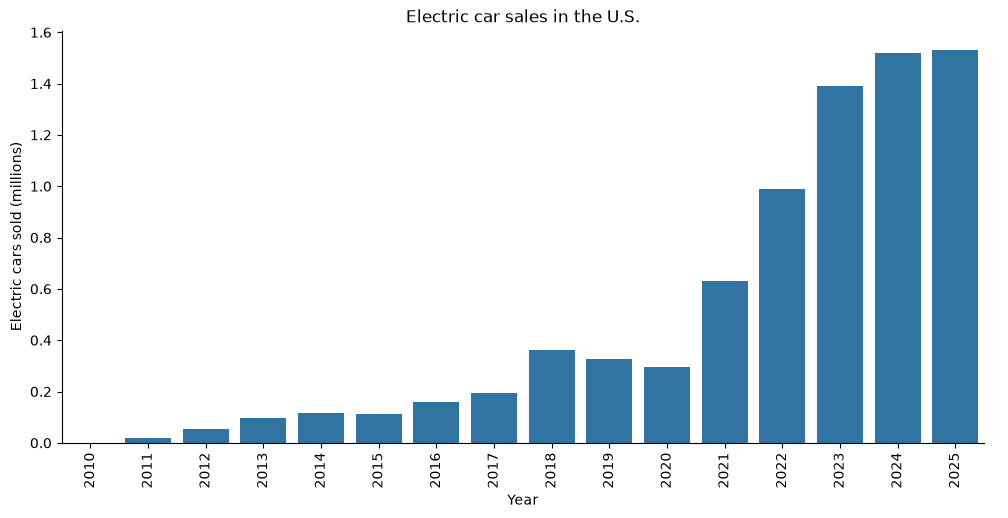

In [3]:
# This bar chart shows that the sales of electric vehicles have been increasing over the years
g = sb.catplot(x="Year", y="Electric cars", data=USDF, aspect=2, kind="bar")
g.set_xticklabels(rotation=90)
g.set(ylabel="Electric cars sold (millions)", title="Electric car sales in the U.S.")
g.ax.yaxis.set_major_formatter(lambda v, _: f"{v / 1e6:.1f}")

## 2. What does it cost per year to charge an EV vs. fuel a gas car?
Prices come from the EIA API. Your API key is read from a `.env` file (`EIA_API_KEY=your_key`) so it is not uploaded to GitHub. Get a free key at https://www.eia.gov/opendata/register.php

In [4]:
# Read the EIA API key from the environment or from the local .env file
apiKey = os.environ.get("EIA_API_KEY")
if not apiKey and Path(".env").exists():
    for line in Path(".env").read_text().splitlines():
        if line.startswith("EIA_API_KEY="):
            apiKey = line.split("=", 1)[1].strip()
if not apiKey:
    raise RuntimeError("Add your EIA API key to a .env file in this folder: EIA_API_KEY=your_key")

In [5]:
# https://www.eia.gov/opendata/
# this request gives the average residential price per kilowatt-hour for each state, every year
Cost = requests.get(
    "https://api.eia.gov/v2/electricity/retail-sales/data/",
    params={
        "api_key": apiKey,
        "frequency": "annual",
        "data[0]": "price",
        "facets[sectorid][]": "RES",
        "start": 2012,
        "end": 2024,
        "sort[0][column]": "period",
        "sort[0][direction]": "desc",
        "length": 5000,
    },
).json()

In [6]:
# costDF contains the average residential electricity price for each U.S. state, 2012-2024
costDF = pd.DataFrame(Cost["response"]["data"])
# The API also returns regional rows (e.g. "WNC" = West North Central) and a U.S. total ("US").
# Keep only the 50 states + DC (two-letter codes) so regions are not counted twice.
costDF = costDF[(costDF["stateid"].str.len() == 2) & (costDF["stateid"] != "US")]
costDF

,period,stateid,stateDescription,sectorid,sectorName,price,price-units
0,2024,AK,Alaska,RES,residential,24.82,cents per kilowatt-hour
1,2024,AL,Alabama,RES,residential,15.18,cents per kilowatt-hour
2,2024,AR,Arkansas,RES,residential,12.32,cents per kilowatt-hour
3,2024,AZ,Arizona,RES,residential,14.91,cents per kilowatt-hour
4,2024,CA,California,RES,residential,31.97,cents per kilowatt-hour
...,...,...,...,...,...,...,...
799,2012,VT,Vermont,RES,residential,17.01,cents per kilowatt-hour
800,2012,WA,Washington,RES,residential,8.53,cents per kilowatt-hour
801,2012,WI,Wisconsin,RES,residential,13.19,cents per kilowatt-hour
804,2012,WV,West Virginia,RES,residential,9.85,cents per kilowatt-hour


In [7]:
# to avoid errors, this removes any character that is not a digit or a decimal point
costDF["price"] = costDF["price"].astype(str).str.replace(r"[^\d.]", "", regex=True)
costDF["price"] = pd.to_numeric(costDF["price"], errors="coerce")
# groups by year ("period") and takes the average price across states
AvgCostPerK = costDF.groupby("period").agg({"price": "mean"})
# price units are cents per kilowatt-hour
AvgCostPerK

,price
period,
2012,12.390000
2013,12.632353
2014,13.080392
2015,13.226863
2016,13.044400
2017,13.535882
2018,13.632745
2019,13.766471
2020,13.808431


In [8]:
# What was the average cost of charging an electric vehicle annually?
# on average, electric vehicles use about 0.3 kWh per mile; 12,000 miles driven per year;
# 0.01 converts cents to dollars. Assumes all charging is done at home at residential rates.
AvgCostPerK["annualcost"] = (((AvgCostPerK["price"] * 0.3) * 0.01) * 12000).round(2)
AvgCostPerK

,price,annualcost
period,,
2012,12.390000,446.04
2013,12.632353,454.76
2014,13.080392,470.89
2015,13.226863,476.17
2016,13.044400,469.60
2017,13.535882,487.29
2018,13.632745,490.78
2019,13.766471,495.59
2020,13.808431,497.10


In [9]:
# what about for a fuel-powered car?
# costGas gets the national average price of regular gasoline each year
costGas = requests.get(
    "https://api.eia.gov/v2/petroleum/pri/gnd/data/",
    params={
        "api_key": apiKey,
        "frequency": "annual",
        "data[0]": "value",
        "facets[product][]": "EPMR",
        "facets[duoarea][]": "NUS",
        "start": 2012,
        "end": 2024,
        "sort[0][column]": "period",
        "sort[0][direction]": "desc",
        "length": 5000,
    },
).json()

In [10]:
# costGasDF contains the U.S. average price of regular gasoline (dollars per gallon), 2012-2024
costGasDF = pd.DataFrame(costGas["response"]["data"]).sort_values(by="period", ascending=True)
costGasDF

,period,duoarea,area-name,product,product-name,process,process-name,series,series-description,value,units
12,2012,NUS,U.S.,EPMR,Regular Gasoline,PTE,Retail Sales,EMM_EPMR_PTE_NUS_DPG,U.S. Regular All Formulations Retail Gasoline ...,3.618,$/GAL
11,2013,NUS,U.S.,EPMR,Regular Gasoline,PTE,Retail Sales,EMM_EPMR_PTE_NUS_DPG,U.S. Regular All Formulations Retail Gasoline ...,3.505,$/GAL
10,2014,NUS,U.S.,EPMR,Regular Gasoline,PTE,Retail Sales,EMM_EPMR_PTE_NUS_DPG,U.S. Regular All Formulations Retail Gasoline ...,3.358,$/GAL
9,2015,NUS,U.S.,EPMR,Regular Gasoline,PTE,Retail Sales,EMM_EPMR_PTE_NUS_DPG,U.S. Regular All Formulations Retail Gasoline ...,2.429,$/GAL
8,2016,NUS,U.S.,EPMR,Regular Gasoline,PTE,Retail Sales,EMM_EPMR_PTE_NUS_DPG,U.S. Regular All Formulations Retail Gasoline ...,2.143,$/GAL
7,2017,NUS,U.S.,EPMR,Regular Gasoline,PTE,Retail Sales,EMM_EPMR_PTE_NUS_DPG,U.S. Regular All Formulations Retail Gasoline ...,2.415,$/GAL
6,2018,NUS,U.S.,EPMR,Regular Gasoline,PTE,Retail Sales,EMM_EPMR_PTE_NUS_DPG,U.S. Regular All Formulations Retail Gasoline ...,2.719,$/GAL
5,2019,NUS,U.S.,EPMR,Regular Gasoline,PTE,Retail Sales,EMM_EPMR_PTE_NUS_DPG,U.S. Regular All Formulations Retail Gasoline ...,2.604,$/GAL
4,2020,NUS,U.S.,EPMR,Regular Gasoline,PTE,Retail Sales,EMM_EPMR_PTE_NUS_DPG,U.S. Regular All Formulations Retail Gasoline ...,2.168,$/GAL
3,2021,NUS,U.S.,EPMR,Regular Gasoline,PTE,Retail Sales,EMM_EPMR_PTE_NUS_DPG,U.S. Regular All Formulations Retail Gasoline ...,3.008,$/GAL


In [11]:
# to avoid errors, this removes any character that is not a digit or a decimal point
costGasDF["value"] = costGasDF["value"].astype(str).str.replace(r"[^\d.]", "", regex=True)
costGasDF["value"] = pd.to_numeric(costGasDF["value"], errors="coerce")
# groups by year ("period") and takes the average price
AvgCostPerG = costGasDF.groupby("period").agg({"value": "mean"})
# price units are dollars per gallon
AvgCostPerG

,value
period,
2012,3.618
2013,3.505
2014,3.358
2015,2.429
2016,2.143
2017,2.415
2018,2.719
2019,2.604
2020,2.168


In [12]:
# What is the average cost of using gas annually?
# 0.04: average gallons used per mile (about 25 miles per gallon)
# 12000: average number of miles driven annually
AvgCostPerG["annualcost"] = ((AvgCostPerG["value"] * 0.04) * 12000).round(2)
AvgCostPerG

,value,annualcost
period,,
2012,3.618,1736.64
2013,3.505,1682.40
2014,3.358,1611.84
2015,2.429,1165.92
2016,2.143,1028.64
2017,2.415,1159.20
2018,2.719,1305.12
2019,2.604,1249.92
2020,2.168,1040.64


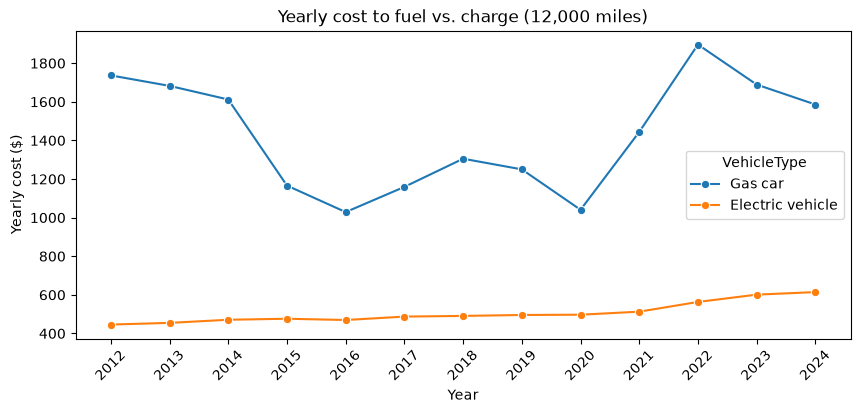

In [13]:
# Both lines on one chart with the same scale so the difference is easy to see
annualCostDF = pd.concat([
    AvgCostPerG[["annualcost"]].assign(VehicleType="Gas car"),
    AvgCostPerK[["annualcost"]].assign(VehicleType="Electric vehicle"),
]).reset_index()
ax = sb.lineplot(x="period", y="annualcost", hue="VehicleType", data=annualCostDF, marker="o")
ax.set(xlabel="Year", ylabel="Yearly cost ($)", title="Yearly cost to fuel vs. charge (12,000 miles)")
ax.tick_params(axis="x", rotation=45)

## 3. How do CO2 emissions compare?

In [14]:
# what is the CO2 emission of vehicles in the US?
# https://www.fueleconomy.gov/feg/download.shtml
vehiclesDF = pd.read_csv(DATA / "vehicles.csv", low_memory=False)
# to make the data frame smaller and simpler, keep only id, fuelType, co2TailpipeGpm, make, model and year
vehiclesDF = vehiclesDF[["id", "fuelType", "co2TailpipeGpm", "make", "model", "year"]]
vehiclesDF

,id,fuelType,co2TailpipeGpm,make,model,year
0,1,Regular,423.190476,Alfa Romeo,Spider Veloce 2000,1985
1,10,Regular,807.909091,Ferrari,Testarossa,1985
2,100,Regular,329.148148,Dodge,Charger,1985
3,1000,Regular,807.909091,Dodge,B150/B250 Wagon 2WD,1985
4,10000,Premium,467.736842,Subaru,Legacy AWD Turbo,1993
...,...,...,...,...,...,...
50642,9995,Regular,403.954545,Subaru,Legacy,1993
50643,9996,Regular,386.391304,Subaru,Legacy,1993
50644,9997,Regular,423.190476,Subaru,Legacy AWD,1993
50645,9998,Regular,423.190476,Subaru,Legacy AWD,1993


In [15]:
# regularGasVehiclesDF has vehicles that use regular or premium gasoline
regularGasVehiclesDF = vehiclesDF[vehiclesDF["fuelType"].isin(["Regular", "Premium"])]

In [16]:
# which vehicles have the highest tailpipe CO2 emissions (grams per mile)?
HighestDf = regularGasVehiclesDF.sort_values("co2TailpipeGpm", ascending=False).head(10)
HighestDf

,id,fuelType,co2TailpipeGpm,make,model,year
34522,4141,Premium,1269.571429,Lamborghini,Countach,1988
7901,1711,Premium,1269.571429,Lamborghini,Countach,1986
21057,2914,Premium,1269.571429,Lamborghini,Countach,1987
46664,6413,Premium,1269.571429,Lamborghini,Countach,1990
45390,5267,Premium,1269.571429,Lamborghini,Countach,1989
45859,569,Regular,1110.875000,Rolls-Royce,Silver Spur Limousine,1985
42993,491,Regular,1110.875000,Maserati,Quattroporte,1985
42882,49,Regular,1110.875000,Aston Martin,Saloon/Vantage/Volante,1985
30635,379,Regular,1110.875000,Rolls-Royce,Camargue,1985
11734,2056,Regular,1110.875000,Rolls-Royce,Camargue,1986


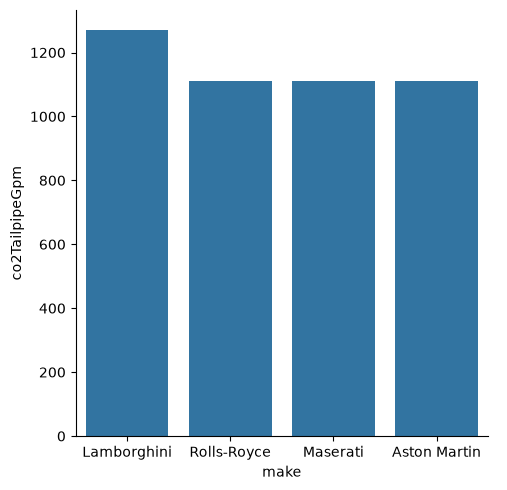

In [17]:
sb.catplot(x="make", y="co2TailpipeGpm", data=HighestDf, kind="bar", height=5, aspect=1)

In [18]:
# which vehicles have the lowest tailpipe CO2 emissions?
minDF = regularGasVehiclesDF.sort_values("co2TailpipeGpm", ascending=True).head(10)
minDF

,id,fuelType,co2TailpipeGpm,make,model,year
44541,50501,Regular,148.0,Toyota,Prius,2027
37510,44138,Regular,151.0,Hyundai,Ioniq Blue,2022
36897,43571,Regular,151.0,Hyundai,Ioniq Blue,2021
33560,40536,Regular,154.0,Hyundai,Ioniq Blue,2019
32539,39614,Regular,154.0,Hyundai,Ioniq Blue,2018
35439,42243,Regular,154.0,Hyundai,Ioniq Blue,2020
31285,38485,Regular,154.0,Hyundai,Ioniq Blue,2017
42731,48861,Regular,155.0,Toyota,Prius,2025
43211,49301,Regular,155.0,Toyota,Prius,2026
40941,47243,Regular,155.0,Toyota,Prius,2024


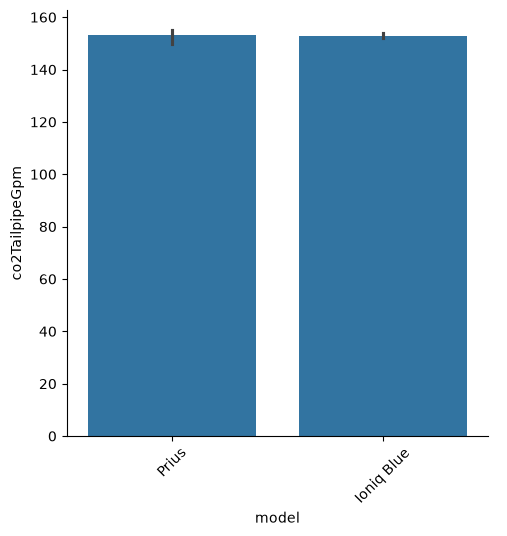

In [19]:
sb.catplot(x="model", y="co2TailpipeGpm", data=minDF, kind="bar", height=5, aspect=1).set_xticklabels(rotation=45)

In [20]:
# average CO2 emissions for gasoline vehicles (grams per mile)
co2EmissionsforRegular = regularGasVehiclesDF["co2TailpipeGpm"].mean()
co2EmissionsDF = pd.DataFrame(columns=["VehicleType", "co2"])
co2EmissionsDF.loc[0] = ["Gas car", co2EmissionsforRegular]
co2EmissionsDF

,VehicleType,co2
0,Gas car,458.473451


In [21]:
# https://ourworldindata.org/travel-carbon-footprint
co2EmissionsforEV = pd.read_csv(DATA / "carbon-footprint-travel-mode.csv")
co2EmissionsforEV

,Entity,Year,Transport emissions per kilometer traveled
0,Bus (average),2022,96.50
1,Bus (local London),2022,79.36
2,Coach (bus),2022,27.33
3,Diesel car,2022,170.82
4,Domestic flight,2022,245.87
5,Electric car,2022,47.09
6,Eurostar (to Paris),2022,4.46
7,Ferry (foot passenger),2022,18.74
8,London Underground,2022,27.81
9,Long-haul flight,2022,147.87


In [22]:
# converting emissions per kilometer to emissions per mile
# it is multiplied by 1.609344 because that is the number of kilometers in a mile
co2EmissionsforEV["Transport emissions per mile traveled"] = (
    co2EmissionsforEV["Transport emissions per kilometer traveled"] * 1.609344
)
co2EmissionsforEV

,Entity,Year,Transport emissions per kilometer traveled,Transport emissions per mile traveled
0,Bus (average),2022,96.50,155.301696
1,Bus (local London),2022,79.36,127.717540
2,Coach (bus),2022,27.33,43.983372
3,Diesel car,2022,170.82,274.908142
4,Domestic flight,2022,245.87,395.689409
5,Electric car,2022,47.09,75.784009
6,Eurostar (to Paris),2022,4.46,7.177674
7,Ferry (foot passenger),2022,18.74,30.159107
8,London Underground,2022,27.81,44.755857
9,Long-haul flight,2022,147.87,237.973697


In [23]:
# look up the electric car row by name (not by position) so it stays correct if the data changes
evCo2 = co2EmissionsforEV.loc[
    co2EmissionsforEV["Entity"] == "Electric car", "Transport emissions per mile traveled"
].iloc[0]
co2EmissionsDF.loc[1] = ["Electric Vehicle", evCo2]
# CO2 emissions per vehicle type, in grams per mile
co2EmissionsDF

,VehicleType,co2
0,Gas car,458.473451
1,Electric Vehicle,75.784009


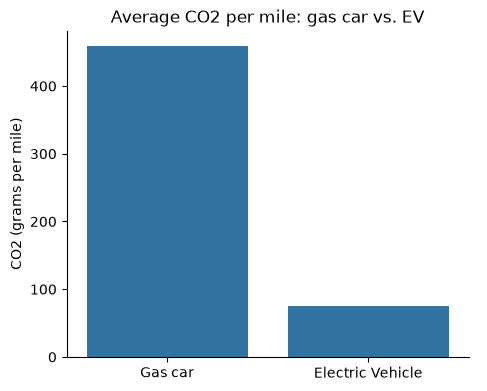

In [24]:
g = sb.catplot(x="VehicleType", y="co2", data=co2EmissionsDF, kind="bar", height=4, aspect=1.2)
g.set(xlabel="", ylabel="CO2 (grams per mile)", title="Average CO2 per mile: gas car vs. EV")